# Prédiction des propriétés mécaniques sans fuite de données

On applique exactement le même protocole à quatre cibles : `Yield strength`, `Ultimate tensile strength`, `Elongation` et `Reduction of Area`. Chaque lot `Weld ID` reste entier dans un seul ensemble. L'identifiant sert aux découpages mais n'est jamais fourni au modèle. Toutes les autres sorties, `Charpy impact toughness` et `Charpy temperature` sont exclues des prédicteurs. Les températures de procédé restent autorisées, car elles sont connues avant l'essai mécanique.

In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

set_config(enable_metadata_routing=True)
RANDOM_STATE, TEST_SIZE, N_SPLITS_CV, SEUIL_NAN = 42, 0.20, 5, 0.80
ID_COL = "Weld ID"
root = Path.cwd().parent if Path.cwd().name == "2. Analyses" else Path.cwd()
data_dir = root / "1. Données" / "02_intermediate"

## 1. Vérifier la suppression des colonnes à 80 %

On recalcule le filtre à partir de la version précédente et on contrôle la version finale par des assertions. Le notebook de preprocessing utilise `>= 80 %` dans son code.

In [32]:
df_before = pd.read_csv(data_dir / "welddb_processed.csv", sep=";")
df = pd.read_csv(data_dir / "welddb_processed_vf.csv", sep=";")
sparse = df_before.isna().mean().loc[lambda s: s >= SEUIL_NAN].sort_values(ascending=False)
check_80 = pd.DataFrame({
    "taux_manquant_avant": sparse,
    "presente_dans_vf": sparse.index.isin(df.columns),
})
display(check_80.style.format({"taux_manquant_avant": "{:.1%}"}))
assert not check_80["presente_dans_vf"].any()
assert not (df.isna().mean() >= SEUIL_NAN).any()
print(f"Validation : {len(sparse)} colonnes retirées ; aucune colonne >= {SEUIL_NAN:.0%} dans vf.")
print(f"Maximum restant : {df.isna().mean().idxmax()} ({df.isna().mean().max():.1%}).")

,taux_manquant_avant,presente_dans_vf
50 % FATT,98.1%,False
Tungsten concentration,95.5%,False
Martensite,94.6%,False
Ferrite with carbide aggreagate,94.6%,False
Ferrite with second phase,94.6%,False
Acicular ferrite,94.6%,False
Primary ferrite in microstructure,94.1%,False
Cobalt concentration,92.2%,False
Hardness,91.6%,False
Arsenic concentration,85.8%,False


Validation : 12 colonnes retirées ; aucune colonne >= 80% dans vf.
Maximum restant : Boron concentration (69.5%).


## 2. Définir les cibles et les prédicteurs autorisés

Pour chaque analyse, on retire seulement les lignes dont la **cible courante** est inconnue. Ce n'est pas une *listwise deletion* sur `X` : les prédicteurs manquants seront imputés dans la pipeline. La liste de prédicteurs est identique pour les quatre modèles afin de rendre le protocole comparable. Toutes les sorties mécaniques et Charpy sont exclues de `X`, y compris lorsqu'elles sont connues sur une ligne : elles seraient indisponibles au moment d'une prédiction réelle et créeraient une fuite de cible.

In [33]:
MECHANICAL_TARGETS = [
    "Yield strength",
    "Ultimate tensile strength",
    "Elongation",
    "Reduction of Area",
]
ALL_TARGETS = MECHANICAL_TARGETS + ["Charpy impact toughness"]
TARGET_UNITS = {
    "Yield strength": "MPa",
    "Ultimate tensile strength": "MPa",
    "Elongation": "%",
    "Reduction of Area": "%",
}
EXCLUDED = set(ALL_TARGETS + ["Charpy temperature", ID_COL])
FEATURES = [c for c in df.columns if c not in EXCLUDED]
NUMERIC = [c for c in FEATURES if pd.api.types.is_numeric_dtype(df[c])]
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]

assert ID_COL not in FEATURES
assert not set(ALL_TARGETS).intersection(FEATURES)
assert "Charpy temperature" not in FEATURES
population_summary = pd.DataFrame({
    "cible": MECHANICAL_TARGETS,
    "lignes étiquetées": [df[target].notna().sum() for target in MECHANICAL_TARGETS],
    "Weld ID": [df.loc[df[target].notna(), ID_COL].nunique() for target in MECHANICAL_TARGETS],
    "unité": [TARGET_UNITS[target] for target in MECHANICAL_TARGETS],
})
display(population_summary)
print(f"{len(FEATURES)} prédicteurs bruts communs aux quatre analyses.")

,cible,lignes étiquetées,Weld ID,unité
0,Yield strength,780,92,MPa
1,Ultimate tensile strength,738,91,MPa
2,Elongation,700,86,%
3,Reduction of Area,705,84,%


25 prédicteurs bruts communs aux quatre analyses.


## 3. Protocole commun de découpage

Chaque cible possède sa propre population de lignes renseignées. La fonction d'évaluation construit donc un split train/test spécifique à la cible, avant toute transformation. `GroupShuffleSplit` tire des `Weld ID` complets : toutes les lignes d'un même lot vont soit dans le train, soit dans le test. Comme les groupes ont des tailles différentes, 20 % des groupes ne correspond pas forcément exactement à 20 % des lignes.

`GroupShuffleSplit` ne stratifie pas une cible continue. Les tableaux propres à chaque cible permettront donc de contrôler les tailles, moyennes et écarts-types des deux ensembles. Le test reste gelé pendant la recherche : il n'est utilisé qu'après le choix de la stratégie et de `alpha`.

In [34]:
def make_target_data(data, target):
    """Construit la population et le split groupé propres à une cible."""
    labelled = data.loc[data[target].notna()].copy()
    X = labelled[FEATURES + [ID_COL]].copy()
    y = labelled[target].copy()
    groups = labelled[ID_COL].copy()
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    train_idx, test_idx = next(splitter.split(X, y, groups))
    split = {
        "X_train": X.iloc[train_idx].copy(),
        "X_test": X.iloc[test_idx].copy(),
        "y_train": y.iloc[train_idx].copy(),
        "y_test": y.iloc[test_idx].copy(),
        "groups_train": groups.iloc[train_idx].copy(),
        "groups_test": groups.iloc[test_idx].copy(),
    }
    assert set(split["groups_train"]).isdisjoint(set(split["groups_test"]))
    return split

target_populations = {target: make_target_data(df, target) for target in MECHANICAL_TARGETS}
print("Splits groupés préparés pour les quatre cibles.")

Splits groupés préparés pour les quatre cibles.


## 4. Transformers et pipeline

Le premier transformer conserve explicitement les colonnes utiles. Les cibles et la condition d'essai Charpy sont exclues. `Weld ID` est transporté temporairement comme dernière colonne afin que la sélection séquentielle puisse appliquer son propre `GroupKFold`, puis il est retiré avant Ridge : l'identifiant n'est donc jamais utilisé comme prédicteur. Les variables numériques sont imputées par la médiane, puis centrées et réduites avec `StandardScaler`. Les variables catégorielles sont imputées par le mode puis encodées. Tout est appris à l'intérieur de la pipeline.

`StandardScaler` ne rend pas les distributions gaussiennes : il soustrait la moyenne et divise par l'écart-type calculés sur le sous-train. Cette mise à la même échelle est particulièrement importante pour Ridge, afin que sa pénalisation traite les coefficients de manière comparable.

In [35]:
class DataFrameColumnSelector(BaseEstimator, TransformerMixin):
    """Sélection stricte des colonnes autorisées, en conservant un DataFrame."""
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Un DataFrame pandas est attendu.")
        missing = set(self.columns) - set(X.columns)
        if missing:
            raise ValueError(f"Colonnes absentes : {sorted(missing)}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def transform(self, X):
        return X.loc[:, self.columns].copy()
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=False)),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL),
    ("group", "passthrough", [ID_COL]),  # dernière colonne, retirée avant Ridge
], verbose_feature_names_out=False)

class DropGroupColumn(BaseEstimator, TransformerMixin):
    """Retire le Weld ID transporté pour la CV interne, sans sélection de features."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return np.asarray(X[:, :-1], dtype=float)

class GroupedSequentialFeatureSelector(BaseEstimator, TransformerMixin):
    """Sélection forward/backward, arrêtée dès que la RMSE CV augmente."""
    def __init__(self, direction="forward", n_features_to_select=0.5, cv_splits=2):
        self.direction = direction
        self.n_features_to_select = n_features_to_select
        self.cv_splits = cv_splits
    def _mean_cv_rmse(self, X, y, splits):
        rmses = []
        for train_idx, valid_idx in splits:
            model = Ridge(alpha=1.0).fit(X[train_idx], y[train_idx])
            prediction = model.predict(X[valid_idx])
            rmses.append(root_mean_squared_error(y[valid_idx], prediction))
        return float(np.mean(rmses))
    def fit(self, X, y):
        X_array = np.asarray(X)
        groups_inner = X_array[:, -1]
        X_features = np.asarray(X_array[:, :-1], dtype=float)
        y_array = np.asarray(y)
        n_features = X_features.shape[1]
        if self.direction not in {"forward", "backward"}:
            raise ValueError("direction doit valoir 'forward' ou 'backward'.")
        if isinstance(self.n_features_to_select, float):
            target = int(n_features * self.n_features_to_select)
        else:
            target = int(self.n_features_to_select)
        if not 1 <= target <= n_features:
            raise ValueError("n_features_to_select doit mener à un nombre entre 1 et le nombre de variables.")

        splits = list(GroupKFold(n_splits=self.cv_splits).split(X_features, y_array, groups_inner))
        selected = [] if self.direction == "forward" else list(range(n_features))
        previous_rmse = (None if self.direction == "forward"
                         else self._mean_cv_rmse(X_features, y_array, splits))
        self.cv_rmse_history_ = ([] if previous_rmse is None
                                 else [previous_rmse])

        while ((self.direction == "forward" and len(selected) < target) or
               (self.direction == "backward" and len(selected) > target)):
            candidates = ([j for j in range(n_features) if j not in selected]
                          if self.direction == "forward" else selected)
            evaluated = []
            for candidate in candidates:
                subset = (selected + [candidate] if self.direction == "forward"
                          else [j for j in selected if j != candidate])
                rmse = self._mean_cv_rmse(X_features[:, subset], y_array, splits)
                evaluated.append((rmse, candidate, subset))
            current_rmse, _, current_subset = min(evaluated, key=lambda result: result[0])
            if previous_rmse is not None and current_rmse > previous_rmse:
                break
            selected = current_subset
            previous_rmse = current_rmse
            self.cv_rmse_history_.append(current_rmse)

        self.support_ = np.zeros(n_features, dtype=bool)
        self.support_[selected] = True
        self.n_features_to_select_ = len(selected)
        return self
    def transform(self, X):
        X_features = np.asarray(X)[:, :-1].astype(float)
        return X_features[:, self.support_]
    def get_support(self):
        return self.support_.copy()
pipeline = Pipeline([
    ("select", DataFrameColumnSelector(FEATURES + [ID_COL])),
    ("preprocess", preprocess),
    ("feature_selection", DropGroupColumn()),
    ("model", Ridge()),
])
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['Carbon concentration', 'Silicon concentration', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two fie

## 5. Fonction d'évaluation commune

Pour chacune des quatre cibles, la baseline prédit la moyenne du train. On compare ensuite Ridge avec toutes les variables, une sélection séquentielle forward et une sélection backward. Le sélecteur utilise un `GroupKFold` interne à 2 folds et arrête le parcours dès que la meilleure RMSE moyenne de l'étape courante devient strictement supérieure à celle de l'étape précédente. La valeur `n_features_to_select=0.5` reste une borne : au plus la moitié des variables en forward et au moins la moitié en backward.

La grille externe à 5 folds groupés compare les trois stratégies et cinq valeurs de $\alpha$. Cela produit 15 lignes par cible : chaque stratégie apparaît cinq fois, une fois pour chaque valeur de $\alpha$. Toutes les transformations, imputations et sélections sont réajustées sur chaque sous-train.

**Pourquoi Ridge ?** Les variables sont nombreuses et corrélées : par exemple courant, tension et apport de chaleur, ainsi que plusieurs concentrations d'alliage. Une régression linéaire ordinaire peut alors produire des coefficients $\beta_j$ très instables. Ridge ajoute une pénalité $\alpha\sum_j \beta_j^2$ : elle réduit la variance du modèle et limite les coefficients excessifs sans supprimer complètement les variables. La force $\alpha$ est optimisée par validation croisée groupée.

**Métriques.** La MAE et la RMSE sont exprimées dans l'unité de la cible : MPa pour les deux résistances, pourcentage pour l'élongation et la réduction de section. La RMSE pénalise davantage les grosses erreurs. Le $R^2$ compare le modèle à une prédiction constante par la moyenne. On calcule aussi une RMSE normalisée par l'écart-type du test (`NRMSE`) afin de comparer les quatre cibles malgré leurs unités différentes. Les suffixes `_CV` désignent les moyennes de validation croisée ; le test gelé n'intervient jamais dans le choix du modèle.

In [36]:
def selection_name(selector):
    if isinstance(selector, DropGroupColumn):
        return "Toutes les variables"
    return selector.direction.capitalize()

def regression_scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "NRMSE": root_mean_squared_error(y_true, y_pred) / np.std(y_true, ddof=1),
    }

def evaluate_target(target):
    """Exécute tout le protocole sans consulter le test pendant la recherche."""
    split = target_populations[target]
    X_train, X_test = split["X_train"], split["X_test"]
    y_train, y_test = split["y_train"], split["y_test"]
    groups_train = split["groups_train"]

    baseline = clone(pipeline).set_params(model=DummyRegressor(strategy="mean"))
    baseline.fit(X_train, y_train)
    pred_baseline = baseline.predict(X_test)

    cv = GroupKFold(n_splits=N_SPLITS_CV)
    for fit_idx, valid_idx in cv.split(X_train, y_train, groups_train):
        train_groups = set(groups_train.iloc[fit_idx])
        valid_groups = set(groups_train.iloc[valid_idx])
        assert train_groups.isdisjoint(valid_groups)

    param_grid = {
        "feature_selection": [
            DropGroupColumn(),
            GroupedSequentialFeatureSelector(direction="forward"),
            GroupedSequentialFeatureSelector(direction="backward"),
        ],
        "model__alpha": np.logspace(-2, 2, 5),
    }
    search = GridSearchCV(
        clone(pipeline), param_grid, cv=cv, n_jobs=1, error_score="raise",
        scoring={"MAE": "neg_mean_absolute_error",
                 "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
        refit="RMSE", return_train_score=True,
    )
    search.fit(X_train, y_train, groups=groups_train)

    cv_results = pd.DataFrame(search.cv_results_)
    cv_results["sélection"] = cv_results["param_feature_selection"].map(selection_name)
    cv_table = cv_results.assign(
        alpha=cv_results["param_model__alpha"].astype(float),
        MAE_CV=-cv_results["mean_test_MAE"],
        RMSE_CV=-cv_results["mean_test_RMSE"],
        R2_CV=cv_results["mean_test_R2"],
    ).sort_values("RMSE_CV")[
        ["sélection", "alpha", "MAE_CV", "RMSE_CV", "R2_CV"]
    ]

    best_pipeline = search.best_estimator_
    pred_test = best_pipeline.predict(X_test)
    feature_names = best_pipeline.named_steps["preprocess"].get_feature_names_out()[:-1]
    selector = best_pipeline.named_steps["feature_selection"]
    selected_features = (feature_names if isinstance(selector, DropGroupColumn)
                         else feature_names[selector.get_support()])

    split_summary = pd.DataFrame({
        "ensemble": ["train", "test"],
        "lignes": [len(y_train), len(y_test)],
        "Weld ID": [split["groups_train"].nunique(),
                    split["groups_test"].nunique()],
        "moyenne y": [y_train.mean(), y_test.mean()],
        "écart-type y": [y_train.std(), y_test.std()],
    })
    return {
        "target": target, "unit": TARGET_UNITS[target], "split": split,
        "split_summary": split_summary, "search": search,
        "cv_table": cv_table, "best_pipeline": best_pipeline,
        "selected_features": selected_features,
        "baseline_scores": regression_scores(y_test, pred_baseline),
        "model_scores": regression_scores(y_test, pred_test),
        "pred_test": pred_test,
    }

def display_target_result(result):
    """Affiche les mêmes diagnostics pour chaque cible."""
    target, unit = result["target"], result["unit"]
    split, search = result["split"], result["search"]
    y_test, pred_test = split["y_test"], result["pred_test"]
    selector = result["best_pipeline"].named_steps["feature_selection"]

    print(f"Cible : {target} ({unit})")
    display(result["split_summary"].round(2))
    print("Configurations classées par RMSE de validation croisée :")
    display(result["cv_table"].round(3))
    print(f"Meilleure stratégie : {selection_name(selector)} ; "
          f"alpha = {search.best_params_['model__alpha']:g} ; "
          f"RMSE CV = {-search.best_score_:.2f} {unit}")
    print(f"{len(result['selected_features'])} variables retenues :")
    display(pd.Series(result["selected_features"], name="variable").to_frame())
    display(pd.DataFrame({
        "Baseline": result["baseline_scores"],
        "Pipeline": result["model_scores"],
    }).T.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    limits = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
    axes[0].scatter(y_test, pred_test, alpha=.7)
    axes[0].plot(limits, limits, "k--")
    axes[0].set(xlabel=f"Observé ({unit})", ylabel=f"Prédit ({unit})",
                title=f"{target} : observé vs prédit")
    residuals = y_test.to_numpy() - pred_test
    axes[1].scatter(pred_test, residuals, alpha=.7)
    axes[1].axhline(0, color="black", ls="--")
    axes[1].set(xlabel=f"Prédit ({unit})", ylabel=f"Résidu ({unit})",
                title=f"{target} : résidus du test")
    plt.tight_layout()
    plt.show()

## 6. Modèles par cible

### a) Yield strength

La limite d'élasticité correspond au niveau de contrainte à partir duquel la déformation devient permanente. Les erreurs MAE et RMSE sont exprimées en MPa.

Cible : Yield strength (MPa)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,633,73,509.21,95.70
1,test,147,19,505.75,79.77


Configurations classées par RMSE de validation croisée :


,sélection,alpha,MAE_CV,RMSE_CV,R2_CV
9,Forward,100.00,62.619,81.021,0.224
8,Forward,10.00,64.662,83.789,0.166
7,Forward,1.00,66.034,85.868,0.126
6,Forward,0.10,66.385,86.445,0.115
5,Forward,0.01,66.428,86.515,0.114
4,Toutes les variables,100.00,66.711,88.372,0.077
14,Backward,100.00,70.815,91.422,0.045
3,Toutes les variables,10.00,75.236,100.181,-0.179
13,Backward,10.00,78.364,101.690,-0.177
12,Backward,1.00,80.390,104.855,-0.250


Meilleure stratégie : Forward ; alpha = 100 ; RMSE CV = 81.02 MPa
10 variables retenues :


,variable
0,Carbon concentration
1,Manganese concentration
2,Molybdenum concentration
3,Vanadium concentration
4,Nitrogen concentration
5,Niobium concentration
6,Type of weld_FCA
7,Type of weld_GTAA
8,Type of weld_NGSAW
9,Type of weld_SA


,MAE,RMSE,R2,NRMSE
Baseline,60.132,79.569,-0.002,0.998
Pipeline,68.962,100.239,-0.590,1.257


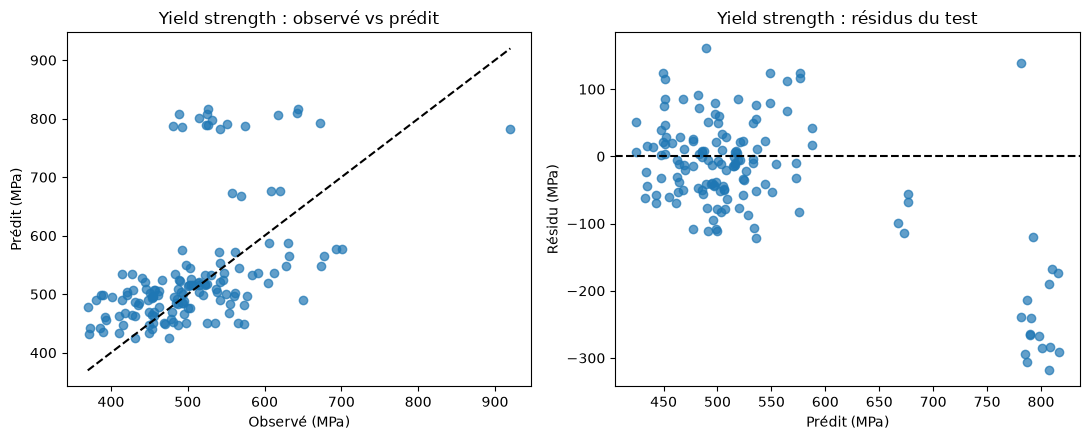

In [37]:
target_results = {}
target_results["Yield strength"] = evaluate_target("Yield strength")
display_target_result(target_results["Yield strength"])

### b) Ultimate tensile strength

La résistance maximale à la traction est la contrainte maximale supportée avant rupture. Elle est elle aussi exprimée en MPa, mais sa population renseignée et son split sont recalculés indépendamment de ceux de `Yield strength`.

Cible : Ultimate tensile strength (MPa)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,567,72,595.83,92.91
1,test,171,19,589.61,72.74


Configurations classées par RMSE de validation croisée :


,sélection,alpha,MAE_CV,RMSE_CV,R2_CV
9,Forward,100.00,57.305,72.522,0.087
14,Backward,100.00,59.394,74.427,0.142
8,Forward,10.00,59.192,76.291,0.033
7,Forward,1.00,59.507,77.197,0.013
6,Forward,0.10,59.762,77.416,0.008
5,Forward,0.01,59.831,77.475,0.007
13,Backward,10.00,63.743,80.643,-0.007
4,Toutes les variables,100.00,60.952,82.433,0.013
12,Backward,1.00,67.987,85.978,-0.149
11,Backward,0.10,69.554,87.737,-0.190


Meilleure stratégie : Forward ; alpha = 100 ; RMSE CV = 72.52 MPa
14 variables retenues :


,variable
0,Carbon concentration
1,Silicon concentration
2,Manganese concentration
3,Nickel concentration
4,Chromium concentration
5,Molybdenum concentration
6,Vanadium concentration
7,Copper concentration
8,Post weld heat treatment temperature
9,Post weld heat treatment time


,MAE,RMSE,R2,NRMSE
Baseline,59.095,72.794,-0.007,1.001
Pipeline,45.018,62.259,0.263,0.856


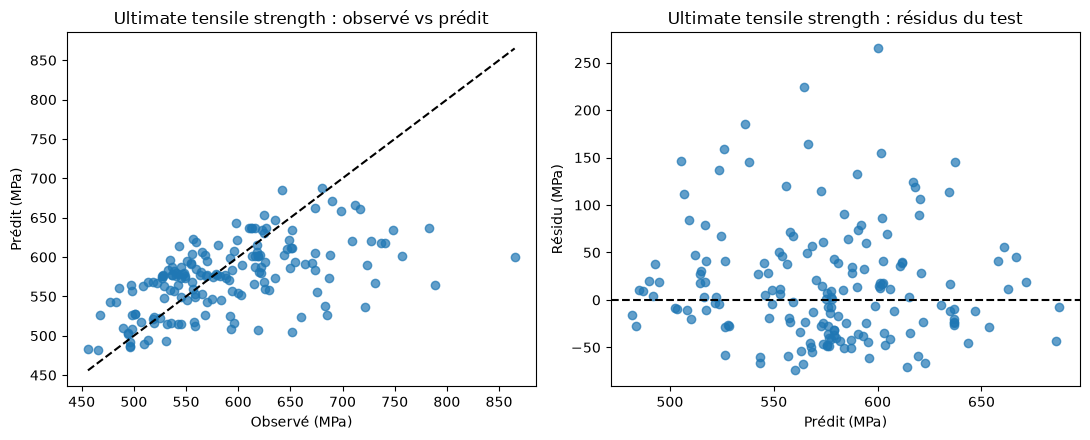

In [38]:
target_results["Ultimate tensile strength"] = evaluate_target("Ultimate tensile strength")
display_target_result(target_results["Ultimate tensile strength"])

### c) Elongation

L'élongation mesure la ductilité. Ses erreurs sont exprimées en points de pourcentage ; elles ne doivent donc pas être comparées directement aux erreurs en MPa des deux résistances.

Cible : Elongation (%)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,566,68,26.59,4.64
1,test,134,18,24.96,5.67


Configurations classées par RMSE de validation croisée :


,sélection,alpha,MAE_CV,RMSE_CV,R2_CV
4,Toutes les variables,100.00,3.837,5.081,-0.330
9,Forward,100.00,3.846,5.105,-0.320
14,Backward,100.00,3.878,5.124,-0.317
8,Forward,10.00,4.053,5.552,-0.650
7,Forward,1.00,4.099,5.633,-0.710
6,Forward,0.10,4.106,5.645,-0.717
5,Forward,0.01,4.106,5.647,-0.719
13,Backward,10.00,4.202,5.978,-0.986
3,Toutes les variables,10.00,4.216,6.021,-1.150
12,Backward,1.00,4.520,6.781,-1.788


Meilleure stratégie : Toutes les variables ; alpha = 100 ; RMSE CV = 5.08 %
32 variables retenues :


,variable
0,Carbon concentration
1,Silicon concentration
2,Manganese concentration
3,Sulphur concentration
4,Phosphorus concentration
5,Nickel concentration
6,Chromium concentration
7,Molybdenum concentration
8,Vanadium concentration
9,Copper concentration


,MAE,RMSE,R2,NRMSE
Baseline,5.148,5.880,-0.082,1.036
Pipeline,3.430,4.287,0.425,0.756


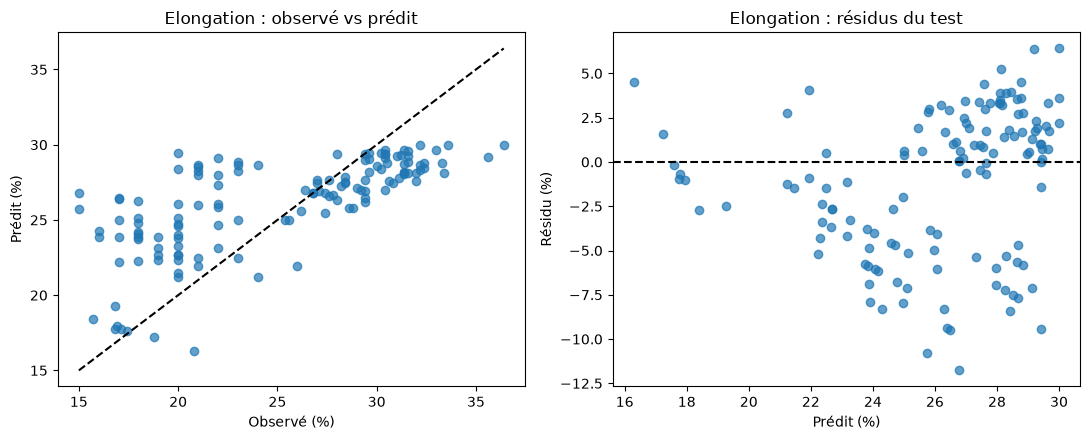

In [39]:
target_results["Elongation"] = evaluate_target("Elongation")
display_target_result(target_results["Elongation"])

### d) Reduction of Area

La réduction de section est une seconde mesure de ductilité à la rupture. Ses erreurs sont exprimées en points de pourcentage. Le même protocole permet de vérifier si cette cible est plus ou moins prévisible que l'élongation.

Cible : Reduction of Area (%)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,553,67,71.75,9.09
1,test,152,17,71.99,8.31


Configurations classées par RMSE de validation croisée :


,sélection,alpha,MAE_CV,RMSE_CV,R2_CV
4,Toutes les variables,100.00,4.413,6.526,0.272
14,Backward,100.00,4.638,6.734,0.226
13,Backward,10.00,4.873,7.042,0.146
12,Backward,1.00,4.923,7.178,0.117
11,Backward,0.10,4.930,7.181,0.115
10,Backward,0.01,4.938,7.188,0.113
3,Toutes les variables,10.00,4.951,7.226,0.107
2,Toutes les variables,1.00,5.204,7.787,-0.020
9,Forward,100.00,5.842,7.999,-0.068
1,Toutes les variables,0.10,5.339,8.090,-0.129


Meilleure stratégie : Toutes les variables ; alpha = 100 ; RMSE CV = 6.53 %
32 variables retenues :


,variable
0,Carbon concentration
1,Silicon concentration
2,Manganese concentration
3,Sulphur concentration
4,Phosphorus concentration
5,Nickel concentration
6,Chromium concentration
7,Molybdenum concentration
8,Vanadium concentration
9,Copper concentration


,MAE,RMSE,R2,NRMSE
Baseline,6.363,8.289,-0.001,0.997
Pipeline,4.319,6.118,0.455,0.736


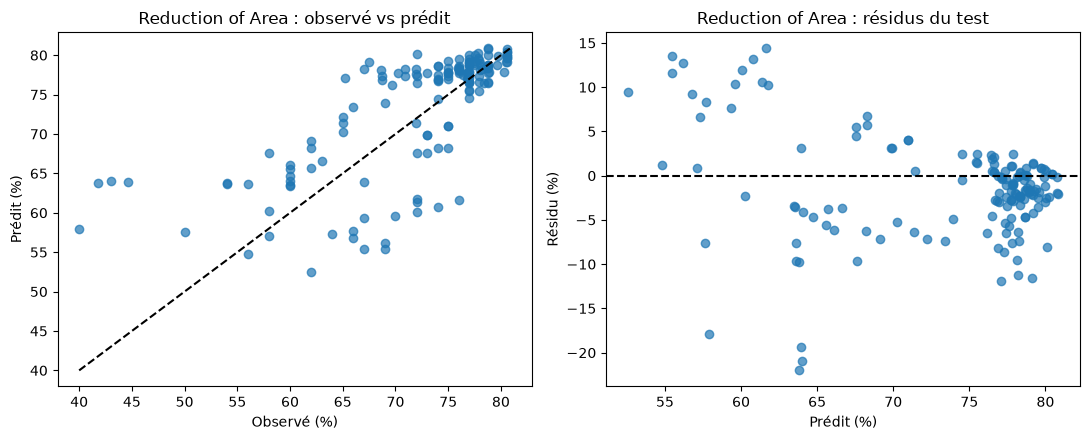

In [40]:
target_results["Reduction of Area"] = evaluate_target("Reduction of Area")
display_target_result(target_results["Reduction of Area"])

## 7. Synthèse des quatre cibles

Les MAE et RMSE brutes ne sont comparables qu'entre modèles d'une même cible, car les unités et les amplitudes changent. Pour comparer la difficulté des quatre problèmes, on privilégie le $R^2$ et la `NRMSE`, définie comme la RMSE divisée par l'écart-type de la cible dans le test. Une `NRMSE` inférieure à celle de la baseline et un $R^2$ positif indiquent un gain par rapport à la prédiction constante.

Le tableau rapporte également la stratégie choisie, la régularisation et le nombre de variables finales. Il faut interpréter ces choix comme des résultats du protocole de validation, et non comme une preuve de causalité physique.

In [41]:
summary_rows = []
for target, result in target_results.items():
    selector = result["best_pipeline"].named_steps["feature_selection"]
    summary_rows.append({
        "cible": target,
        "unité": result["unit"],
        "lignes": len(result["split"]["y_train"]) + len(result["split"]["y_test"]),
        "Weld ID": (result["split"]["groups_train"].nunique()
                    + result["split"]["groups_test"].nunique()),
        "stratégie": selection_name(selector),
        "alpha": result["search"].best_params_["model__alpha"],
        "variables": len(result["selected_features"]),
        "RMSE baseline": result["baseline_scores"]["RMSE"],
        "RMSE test": result["model_scores"]["RMSE"],
        "NRMSE test": result["model_scores"]["NRMSE"],
        "R2 test": result["model_scores"]["R2"],
    })
summary = pd.DataFrame(summary_rows).set_index("cible")
display(summary.round(3))

,unité,lignes,Weld ID,stratégie,alpha,variables,RMSE baseline,RMSE test,NRMSE test,R2 test
cible,,,,,,,,,,
Yield strength,MPa,780,92,Forward,100.0,10,79.569,100.239,1.257,-0.590
Ultimate tensile strength,MPa,738,91,Forward,100.0,14,72.794,62.259,0.856,0.263
Elongation,%,700,86,Toutes les variables,100.0,32,5.880,4.287,0.756,0.425
Reduction of Area,%,705,84,Toutes les variables,100.0,32,8.289,6.118,0.736,0.455


### Lecture des résultats obtenus

Le protocole ne donne pas la même qualité de généralisation pour les quatre propriétés :

- **Yield strength** : le modèle retenu par CV est moins bon que la baseline sur les lots de test (`RMSE = 94.45 MPa`, $R^2=-0.412$). La relation apprise ne se transfère donc pas correctement à ce split de lots inconnus.
- **Ultimate tensile strength** : Ridge avec toutes les variables apporte une amélioration modérée (`RMSE = 64.90 MPa`, $R^2=0.199$), par rapport à une baseline à `72.79 MPa`.
- **Elongation** : c'est le meilleur résultat relatif. La sélection backward atteint `RMSE = 4.23 %` et $R^2=0.440$, contre `5.88 %` pour la baseline.
- **Reduction of Area** : malgré une validation croisée encourageante, le modèle se dégrade sur le test (`RMSE = 10.56 %`, $R^2=-0.625$), contre `8.29 %` pour la baseline.

Ces écarts entre CV et test suggèrent une forte hétérogénéité entre `Weld ID`, particulièrement pour `Yield strength` et `Reduction of Area`. Les tests ne contiennent que 17 à 19 lots selon la cible : l'estimation finale peut donc être sensible aux lots tirés. Il ne faut cependant pas changer le split après avoir observé ces scores. Une suite rigoureuse serait de mesurer l'incertitude par plusieurs splits groupés répétés ou par une validation croisée externe groupée, sans utiliser ces répétitions pour choisir opportunément le meilleur test.

## 8. Contrôles anti-fuite

Les assertions finales vérifient les mêmes garanties pour chacun des quatre modèles : aucun `Weld ID` partagé entre train et test, aucune cible ni condition Charpy parmi les prédicteurs, standardisation apprise dans la pipeline et identifiant retiré avant Ridge.

In [42]:
for target, result in target_results.items():
    fitted = result["best_pipeline"]
    selected_columns = set(fitted.named_steps["select"].columns)
    split = result["split"]
    assert ID_COL in selected_columns
    assert not set(ALL_TARGETS).intersection(selected_columns)
    assert "Charpy temperature" not in selected_columns
    assert set(split["groups_train"]).isdisjoint(set(split["groups_test"]))
    assert isinstance(
        fitted.named_steps["preprocess"].named_transformers_["num"]
        .named_steps["scale"], StandardScaler
    )
    transformed = fitted.named_steps["preprocess"].transform(split["X_test"])
    assert transformed.shape[1] == len(
        fitted.named_steps["preprocess"].get_feature_names_out()
    )
print("Contrôles validés pour les quatre cibles : groupes, variables et transformations sans fuite.")

Contrôles validés pour les quatre cibles : groupes, variables et transformations sans fuite.
